# Lezione 1 - Introduzione alle ANN con PyTorch

Notebook introduttivo sulle **Artificial Neural Networks (ANN)** usando PyTorch e il dataset **Breast Cancer Wisconsin Diagnostic**.

Obiettivi della lezione:

1. esplorare un dataset tabellare;
2. creare split **train / validation / test**;
3. standardizzare le feature;
4. definire funzioni riutilizzabili per training, validation e test;
5. addestrare una ANN minimale con **un solo neurone**;
6. addestrare una ANN con **hidden layer**;
7. confrontare i modelli con loss, accuracy, confusion matrix e classification report.

## 0. Dipendenze

Se il notebook viene eseguito in un ambiente nuovo, installare prima:

```bash
pip install torch scikit-learn pandas matplotlib numpy
```

In [17]:
import importlib.util

required_packages = {
    "torch": "torch",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [pip_name for module_name, pip_name in required_packages.items() if importlib.util.find_spec(module_name) is None]

if missing:
    print("Librerie mancanti:", ", ".join(missing))
    print("Eseguire in una cella separata:")
    print("%pip install " + " ".join(missing))
else:
    print("Tutte le dipendenze sono disponibili.")

Tutte le dipendenze sono disponibili.


In [18]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device in uso:", device)

Device in uso: cpu


## 1. Esplorazione del dataset

Il dataset Breast Cancer Wisconsin Diagnostic contiene misure numeriche ricavate da immagini di agoaspirato mammario.

Il target e binario:

- `0`: malignant;
- `1`: benign.

Questa scelta e utile per una prima ANN con un solo neurone di output.

In [19]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print("Classi:", dict(enumerate(data.target_names)))

X.head()

Shape X: (569, 30)
Shape y: (569,)
Classi: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [20]:
X.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


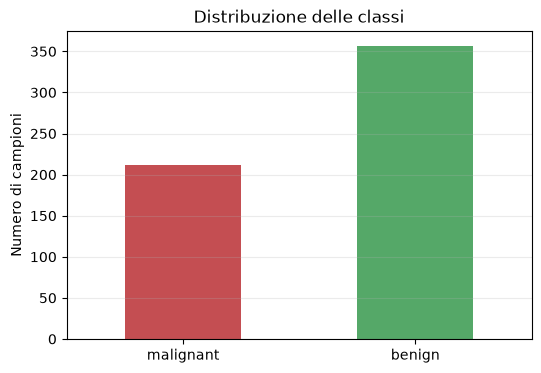

malignant    212
benign       357
Name: count, dtype: int64

In [21]:
class_counts = y.value_counts().sort_index()
class_counts.index = [data.target_names[i] for i in class_counts.index]

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar", color=["#c44e52", "#55a868"])
plt.title("Distribuzione delle classi")
plt.ylabel("Numero di campioni")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.show()

class_counts

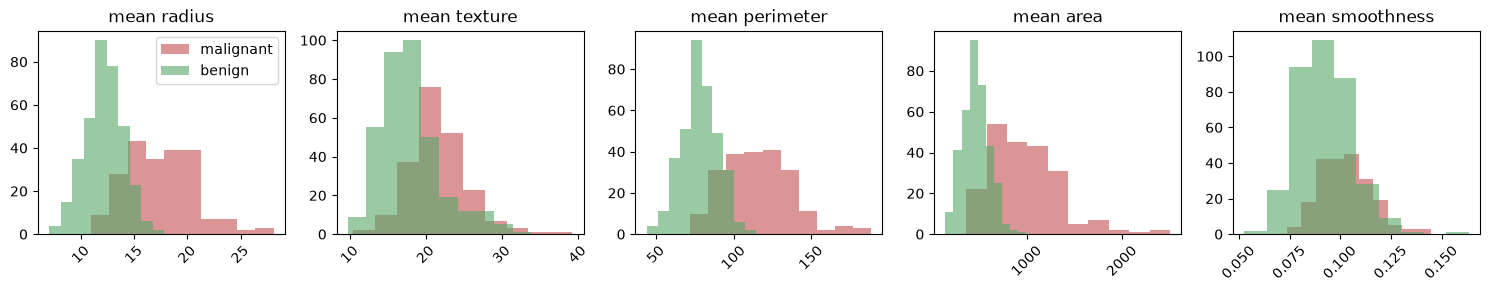

In [22]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
]

plot_data = X[selected_features].copy()
plot_data["target"] = y.map({0: "malignant", 1: "benign"})

fig, axes = plt.subplots(1, len(selected_features), figsize=(15, 3))
for ax, feature in zip(axes, selected_features):
    for label, color in [("malignant", "#c44e52"), ("benign", "#55a868")]:
        ax.hist(plot_data.loc[plot_data["target"] == label, feature], alpha=0.6, label=label, color=color)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. Split train / validation / test

Useremo tre insiemi:

1. **train set**: aggiorna i pesi del modello;
2. **validation set**: controlla il comportamento durante la scelta del modello;
3. **test set**: valutazione finale.

La standardizzazione viene calcolata solo sul train set, poi applicata a validation e test. Questo evita data leakage.

In [25]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train_val,
)
# scaler = StandardScaler(with_mean=False, with_std=False)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

y_train_tensor = torch.tensor(y_train.values.reshape(-1, 1), dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val.values.reshape(-1, 1), dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test.values.reshape(-1, 1), dtype=torch.float32).to(device)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Data Loaders
# ---------------------------------------------------------------------

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)  
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Train:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_test_tensor.shape, y_test_tensor.shape)

Train: torch.Size([341, 30]) torch.Size([341, 1])
Validation: torch.Size([114, 30]) torch.Size([114, 1])
Test: torch.Size([114, 30]) torch.Size([114, 1])


## Funzioni comuni per training, validation e test

Queste funzioni sono pensate per essere riutilizzate in entrambi i notebook.

L'unica differenza tra classificazione binaria e multiclasse viene gestita con il parametro `task`:

- `task="binary"`: output a 1 neurone, `BCEWithLogitsLoss`, sigmoide e soglia 0.5;
- `task="multiclass"`: output a N classi, `CrossEntropyLoss`, softmax e argmax.

In [ ]:
def run_epoch(model, data_loader, criterion, optimizer=None, task="multiclass", threshold=0.5):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for inputs, targets in data_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            logits = model(inputs)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

        if task == "binary":
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= threshold).float()
            correct = (predictions == targets.view_as(predictions)).sum().item()
        elif task == "multiclass":
            predictions = logits.argmax(dim=1)
            correct = (predictions == targets).sum().item()
        else:
            raise ValueError("task deve essere 'binary' oppure 'multiclass'")

        batch_size = inputs.size(0)
        total_loss += loss.item() * batch_size
        total_correct += correct
        total_samples += batch_size

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


def train_model(
    model,
    train_loader,
    val_loader,
    criterion=None,
    task="multiclass",
    epochs=10,
    lr=0.001,
    weight_decay=0.0,
    threshold=0.5,
    optimizer_type="adam"
):
    model = model.to(device)
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss() if task == "binary" else nn.CrossEntropyLoss()

    if optimizer_type == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_type == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError("optimizer_type should be 'adam' or 'sgd'")

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            task=task,
            threshold=threshold,
        )
        val_loss, val_acc = run_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            task=task,
            threshold=threshold,
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoca {epoch + 1:02d}/{epochs} - "
            f"train loss: {train_loss:.4f} - val loss: {val_loss:.4f} - "
            f"train acc: {train_acc:.3f} - val acc: {val_acc:.3f}"
        )

    return history


def evaluate_model(model, data_loader, task="multiclass", threshold=0.5):
    model.eval()
    all_targets = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            logits = model(inputs)

            if task == "binary":
                probabilities = torch.sigmoid(logits).cpu().numpy().reshape(-1)
                predictions = (probabilities >= threshold).astype(int)
                targets_np = targets.cpu().numpy().reshape(-1).astype(int)
            elif task == "multiclass":
                probabilities = torch.softmax(logits, dim=1).cpu().numpy()
                predictions = probabilities.argmax(axis=1)
                targets_np = targets.cpu().numpy().reshape(-1).astype(int)
            else:
                raise ValueError("task deve essere 'binary' oppure 'multiclass'")

            all_targets.extend(targets_np)
            all_predictions.extend(predictions)
            all_probabilities.extend(probabilities)

    y_true = np.array(all_targets)
    y_pred = np.array(all_predictions)
    probabilities = np.array(all_probabilities)
    accuracy = accuracy_score(y_true, y_pred)
    return accuracy, y_true, y_pred, probabilities


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Training loss")
    axes[0].plot(history["val_loss"], label="Validation loss")
    axes[0].set_title(title + " - loss")
    axes[0].set_xlabel("Epoca")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(history["train_accuracy"], label="Training accuracy")
    axes[1].plot(history["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(title + " - accuracy")
    axes[1].set_xlabel("Epoca")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


def plot_loss(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["train_loss"], label="Training loss")
    plt.plot(history["val_loss"], label="Validation loss")
    plt.title(title)
    plt.xlabel("Epoca")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def plot_accuracy(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["train_accuracy"], label="Training accuracy")
    plt.plot(history["val_accuracy"], label="Validation accuracy")
    plt.title(title)
    plt.xlabel("Epoca")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def plot_confusion_matrix(cm, title, class_names, cmap="Blues"):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap=cmap)
    plt.title(title)
    plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
    plt.yticks(range(len(class_names)), class_names)
    plt.xlabel("Predetto")
    plt.ylabel("Reale")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > cm.max() * 0.6 else "black"
            plt.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=8)

    plt.colorbar()
    plt.tight_layout()
    plt.show()

# Parte A - ANN con un solo neurone

Il primo modello ha:

- 30 input, uno per ogni feature;
- 1 neurone di output;
- nessun hidden layer.

Questo modello e una rete neurale minimale ed e molto simile a una regressione logistica.

In [26]:
class SingleNeuronANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.output_layer = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.output_layer(x)

single_neuron_model = SingleNeuronANN(input_dim=X_train_tensor.shape[1]).to(device)
print(single_neuron_model)
print("Numero di parametri:", sum(p.numel() for p in single_neuron_model.parameters()))

SingleNeuronANN(
  (output_layer): Linear(in_features=30, out_features=1, bias=True)
)
Numero di parametri: 31


Epoca 01/250 - train loss: 0.8644 - val loss: 0.7041 - train acc: 0.270 - val acc: 0.588
Epoca 02/250 - train loss: 0.6055 - val loss: 0.5416 - train acc: 0.736 - val acc: 0.860
Epoca 03/250 - train loss: 0.4722 - val loss: 0.4510 - train acc: 0.909 - val acc: 0.877
Epoca 04/250 - train loss: 0.3970 - val loss: 0.3959 - train acc: 0.918 - val acc: 0.904
Epoca 05/250 - train loss: 0.3500 - val loss: 0.3575 - train acc: 0.935 - val acc: 0.904
Epoca 06/250 - train loss: 0.3169 - val loss: 0.3292 - train acc: 0.941 - val acc: 0.904
Epoca 07/250 - train loss: 0.2923 - val loss: 0.3072 - train acc: 0.947 - val acc: 0.912
Epoca 08/250 - train loss: 0.2731 - val loss: 0.2895 - train acc: 0.953 - val acc: 0.912
Epoca 09/250 - train loss: 0.2573 - val loss: 0.2749 - train acc: 0.953 - val acc: 0.912
Epoca 10/250 - train loss: 0.2445 - val loss: 0.2626 - train acc: 0.953 - val acc: 0.930
Epoca 11/250 - train loss: 0.2335 - val loss: 0.2519 - train acc: 0.953 - val acc: 0.930
Epoca 12/250 - train 

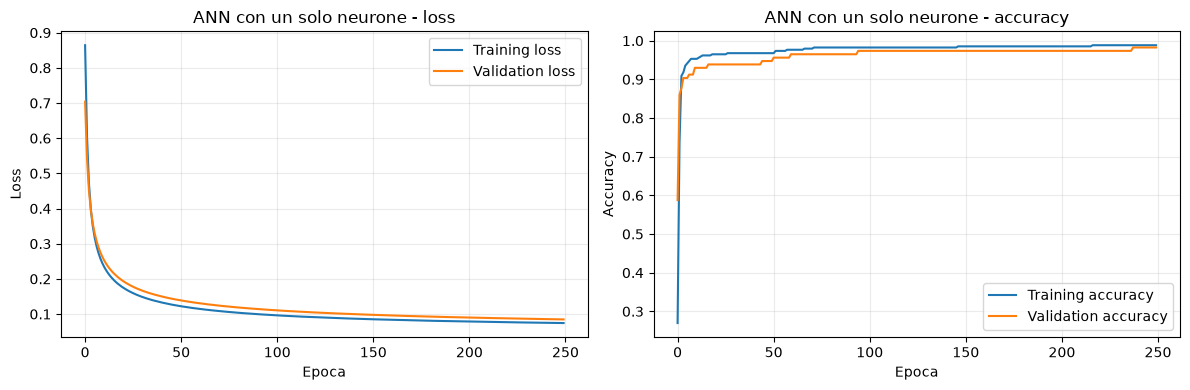

In [27]:
history_single = train_model(
    single_neuron_model,
    train_loader,
    val_loader,
    criterion=nn.BCEWithLogitsLoss(),
    task="binary",
    epochs=250,
    lr=0.01,
    weight_decay=1e-4,
    optimizer_type="sgd"
)

plot_history(history_single, "ANN con un solo neurone")

Accuracy train:      0.988
Accuracy validation: 0.982
Accuracy test:       0.982

Classification report sul test set:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



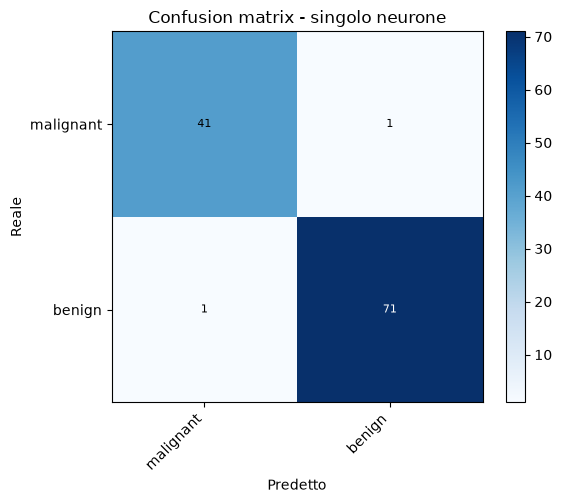

In [28]:
train_acc_single, y_train_true_single, y_train_pred_single, _ = evaluate_model(single_neuron_model, train_loader, task="binary")
val_acc_single, y_val_true_single, y_val_pred_single, _ = evaluate_model(single_neuron_model, val_loader, task="binary")
test_acc_single, y_test_true_single, y_test_pred_single, test_proba_single = evaluate_model(single_neuron_model, test_loader, task="binary")

print(f"Accuracy train:      {train_acc_single:.3f}")
print(f"Accuracy validation: {val_acc_single:.3f}")
print(f"Accuracy test:       {test_acc_single:.3f}")
print("\nClassification report sul test set:")
print(classification_report(y_test_true_single, y_test_pred_single, target_names=data.target_names))

cm_single = confusion_matrix(y_test_true_single, y_test_pred_single)
plot_confusion_matrix(cm_single, "Confusion matrix - singolo neurone", data.target_names)

## 4. Lettura dei pesi del modello semplice

Nel modello a un neurone c'e un peso per ogni feature. Dopo la standardizzazione, il valore assoluto del peso puo dare una prima indicazione didattica delle feature piu influenti.

Non e una spiegazione causale: e solo un modo per leggere i parametri del modello.

In [29]:
weights = single_neuron_model.output_layer.weight.detach().cpu().numpy().reshape(-1)
bias = single_neuron_model.output_layer.bias.detach().cpu().item()

weight_table = pd.DataFrame({
    "feature": data.feature_names,
    "weight": weights,
    "abs_weight": np.abs(weights),
}).sort_values("abs_weight", ascending=False)

print("Bias:", round(bias, 4))
weight_table.head(10)

Bias: 0.4525


,feature,weight,abs_weight
21,worst texture,-0.679278,0.679278
3,mean area,-0.626598,0.626598
10,radius error,-0.607835,0.607835
27,worst concave points,-0.579314,0.579314
1,mean texture,-0.567958,0.567958
20,worst radius,-0.547185,0.547185
22,worst perimeter,-0.521894,0.521894
7,mean concave points,-0.515013,0.515013
2,mean perimeter,-0.475567,0.475567
23,worst area,-0.449619,0.449619


# Parte B - ANN con piu neuroni e hidden layer

Ora aggiungiamo hidden layer. La rete diventa piu flessibile e puo imparare relazioni non lineari.

Architettura:

- input: 30 feature;
- hidden layer 1: 16 neuroni + ReLU;
- hidden layer 2: 8 neuroni + ReLU;
- output: 1 logit.

In [30]:
class MultiNeuronANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            # nn.Dropout(p=0.2),
            nn.ReLU(),
            nn.Linear(8, 1),
        )

    def forward(self, x):
        return self.network(x)



MultiNeuronANN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)
Numero di parametri: 641
Epoca 01/250 - train loss: 0.6714 - val loss: 0.6224 - train acc: 0.393 - val acc: 0.737
Epoca 02/250 - train loss: 0.5410 - val loss: 0.4394 - train acc: 0.897 - val acc: 0.956
Epoca 03/250 - train loss: 0.3260 - val loss: 0.2169 - train acc: 0.953 - val acc: 0.956
Epoca 04/250 - train loss: 0.1505 - val loss: 0.1166 - train acc: 0.968 - val acc: 0.965
Epoca 05/250 - train loss: 0.0891 - val loss: 0.0899 - train acc: 0.974 - val acc: 0.956
Epoca 06/250 - train loss: 0.0705 - val loss: 0.0813 - train acc: 0.988 - val acc: 0.974
Epoca 07/250 - train loss: 0.0631 - val loss: 0.0787 - train acc: 0.988 - val acc: 0.965
Epoca 08/250 - train loss: 0.0588 - val loss: 0.0779 - train acc: 0.988 - val acc: 0.965
Epoca 0

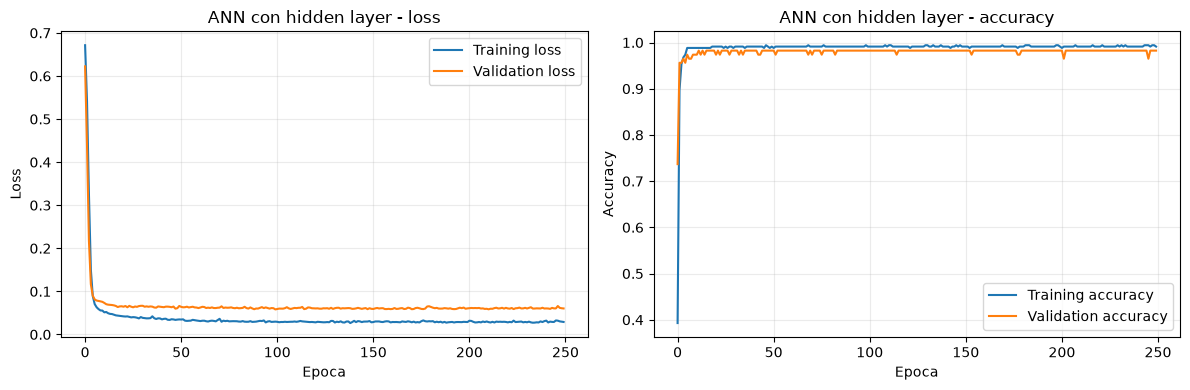

In [31]:
multi_neuron_model = MultiNeuronANN(input_dim=X_train_tensor.shape[1]).to(device)
print(multi_neuron_model)
print("Numero di parametri:", sum(p.numel() for p in multi_neuron_model.parameters()))

history_multi = train_model(
    multi_neuron_model,
    train_loader,
    val_loader,
    criterion=nn.BCEWithLogitsLoss(),
    task="binary",
    epochs=250,
    lr=0.005,
    weight_decay=1e-2,
)

plot_history(history_multi, "ANN con hidden layer")

Accuracy train:      0.991
Accuracy validation: 0.982
Accuracy test:       0.965

Classification report sul test set:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



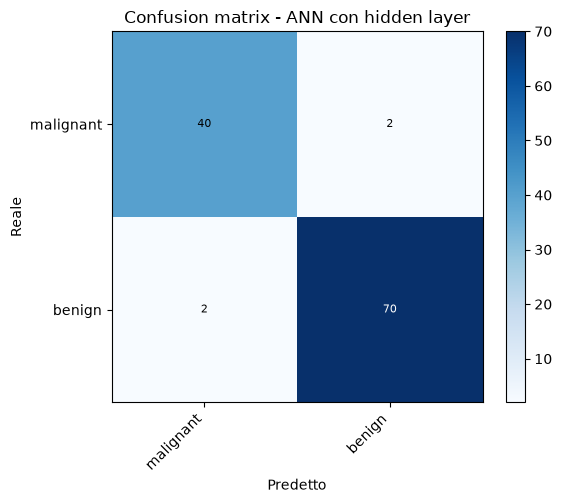

In [32]:
train_acc_multi, y_train_true_multi, y_train_pred_multi, _ = evaluate_model(multi_neuron_model, train_loader, task="binary")
val_acc_multi, y_val_true_multi, y_val_pred_multi, _ = evaluate_model(multi_neuron_model, val_loader, task="binary")
test_acc_multi, y_test_true_multi, y_test_pred_multi, test_proba_multi = evaluate_model(multi_neuron_model, test_loader, task="binary")

print(f"Accuracy train:      {train_acc_multi:.3f}")
print(f"Accuracy validation: {val_acc_multi:.3f}")
print(f"Accuracy test:       {test_acc_multi:.3f}")
print("\nClassification report sul test set:")
print(classification_report(y_test_true_multi, y_test_pred_multi, target_names=data.target_names))

cm_multi = confusion_matrix(y_test_true_multi, y_test_pred_multi)
plot_confusion_matrix(cm_multi, "Confusion matrix - ANN con hidden layer", data.target_names)

## 5. Confronto tra modello semplice e modello piu complesso

Un modello con piu neuroni non e automaticamente migliore. Il confronto va fatto su validation e test set.

In [33]:
comparison = pd.DataFrame({
    "modello": ["Singolo neurone", "ANN hidden layer"],
    "train_accuracy": [train_acc_single, train_acc_multi],
    "validation_accuracy": [val_acc_single, val_acc_multi],
    "test_accuracy": [test_acc_single, test_acc_multi],
    "final_train_loss": [history_single["train_loss"][-1], history_multi["train_loss"][-1]],
    "final_val_loss": [history_single["val_loss"][-1], history_multi["val_loss"][-1]],
    "parametri": [
        sum(p.numel() for p in single_neuron_model.parameters()),
        sum(p.numel() for p in multi_neuron_model.parameters()),
    ],
})

comparison

,modello,train_accuracy,validation_accuracy,test_accuracy,final_train_loss,final_val_loss,parametri
0,Singolo neurone,0.988270,0.982456,0.982456,0.074448,0.084802,31
1,ANN hidden layer,0.991202,0.982456,0.964912,0.029020,0.060367,641


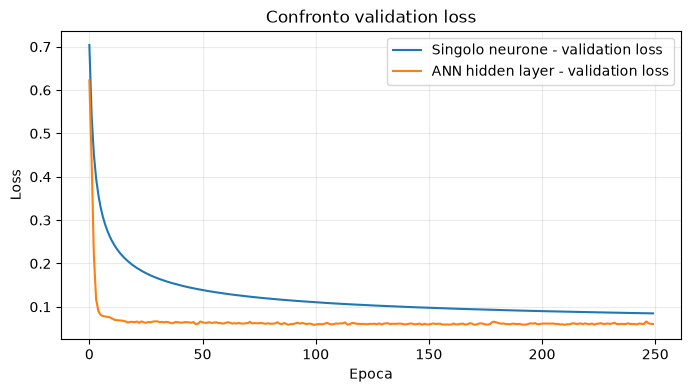

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(history_single["val_loss"], label="Singolo neurone - validation loss")
plt.plot(history_multi["val_loss"], label="ANN hidden layer - validation loss")
plt.title("Confronto validation loss")
plt.xlabel("Epoca")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 6. Esercizi

1. Cambiare il learning rate e osservare train/validation loss.
2. Cambiare il numero di epoche.
3. Aggiungere `Dropout` alla ANN con hidden layer.
4. Cambiare soglia di classificazione da `0.5` a `0.3` o `0.7`.
5. Confrontare accuracy, recall e precision.


## 7. Mini riepilogo

- Una ANN a un solo neurone e un ottimo baseline per classificazione binaria.
- Train, validation e test hanno ruoli diversi.
- La validation loss serve per capire se il modello generalizza durante lo sviluppo.
- Una ANN con hidden layer puo imparare relazioni piu complesse, ma puo anche fare overfitting.
- Il modello migliore non e quello piu grande: e quello che generalizza meglio.